# UCL-specific endpoint and appearance landmarks

**Question:** Which documented UCL episodes support a defensible ahead-of-time prediction study? This stage starts after completed feature consolidation. The database and previous results are preserved. Events are source-documented, not independently clinically adjudicated.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
while not (ROOT / 'src/injury_analysis').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.injury_analysis.ucl_dynamic_common import OUT, CACHE, read_table, valid_checkpoint
pd.set_option('display.max_columns', 20)
def show(name, **kwargs):
    display(read_table(name).head(kwargs.get('rows', 30)))
def plot(name):
    display(Image(filename=str(OUT / 'figures' / (name + '.png')), width=1100))


In [2]:
from src.injury_analysis.ucl_dynamic_data import prepare_data
a, events, specs = prepare_data()
display(pd.Series({'source_appearances':len(a),'primary_UCL_events':int(events.endpoint_primary.sum()),'unique_primary_pitchers':events.loc[events.endpoint_primary,'player_id'].nunique(),'strict_official_events':int(events.endpoint_strict_official.sum()),'expanded_probable_events':int(events.endpoint_expanded.sum())}))

source_appearances          233433
primary_UCL_events             194
unique_primary_pitchers        184
strict_official_events          60
expanded_probable_events       221
dtype: int64

## Outcome specificity and knowledge time

An official non-procedure UCL diagnosis or a bounded compatible MLB procedure link supports the primary endpoint. Procedure-only/recovery text is not enough to establish a new injury. Forearm/flexor presentations can qualify with subsequent compatible evidence. The retrospective event label may use later confirmation; predictors cannot. Surgery date, report date, diagnosis date and earliest event proxy remain separate. No date is called exact biological onset.

In [3]:
show('endpoint_counts', rows=40)
show('ucl_events_by_season', rows=20)

,endpoint_partition,evidence_category,episodes,usable_primary,usable_strict,usable_expanded
0,descriptive_2026,ambiguous_elbow,5,0,0,0
1,descriptive_2026,broader_elbow,76,0,0,0
2,descriptive_2026,confirmed_official_documentation,5,2,2,2
3,descriptive_2026,confirmed_procedure_supported,19,17,0,17
4,descriptive_2026,forearm_without_ucl_confirmation,37,0,0,0
5,descriptive_2026,other_or_unknown_injury,297,0,0,0
6,descriptive_2026,probable_supplemental_documentation,32,0,0,5
7,test,ambiguous_elbow,6,0,0,0
8,test,broader_elbow,123,0,0,0
9,test,confirmed_official_documentation,16,14,14,14


,season,events,pitchers,initial_explicit,procedure_supported,public_date_gap_median
0,2015,11,11,2,11,1.0
1,2016,14,14,2,13,1.0
2,2017,14,14,4,9,0.5
3,2018,21,21,10,15,0.0
4,2019,16,16,7,12,0.0
5,2020,20,20,8,12,0.0
6,2021,2,2,1,2,0.0
7,2022,10,10,3,9,0.0
8,2023,24,24,4,20,0.0
9,2024,20,19,8,16,0.5


In [4]:
cols=['player_name','prediction_reference_date','first_public_indication_date','diagnosis_date','evidence_category','initial_injury_region','linked_procedure_ids','source_publication_archive_verified']
display(events.loc[events.endpoint_primary,cols].head(15))
display(events.loc[events.endpoint_primary,'timing_uncertainty_days'].describe())

,player_name,prediction_reference_date,first_public_indication_date,diagnosis_date,evidence_category,initial_injury_region,linked_procedure_ids,source_publication_archive_verified
3,Joe Nathan,2015-04-07,2015-04-09,NaT,confirmed_procedure_supported,Elbow / UCL,d5065a87cde1f45be4d9e13e8b73307d,False
139,Sergio Santos,2015-06-15,2015-06-19,NaT,confirmed_procedure_supported,Elbow / UCL,c6998310e9e2193c0b455dbcc083dbd9,False
141,Brandon McCarthy,2015-04-26,2015-04-27,2015-04-27,confirmed_official_documentation,Elbow / UCL,c0f42469f659270801d795c0981cc6f0,False
232,Sean Doolittle,2022-04-20,2022-04-20,NaT,confirmed_procedure_supported,Elbow / UCL,675202d18ead64e8447a61faee1ca49e,False
271,Jason Vargas,2015-07-22,2015-07-22,2015-07-22,confirmed_official_documentation,Elbow / UCL,fb422a889c8604ad0985317ee8f2d10f,False
424,Johnny Cueto,2018-07-29,2018-07-30,NaT,confirmed_procedure_supported,Elbow / UCL,872558e4c4862f1a4cc1cc7e7a710814,False
436,Homer Bailey,2015-04-25,2015-04-27,NaT,confirmed_procedure_supported,Elbow / UCL,9c459edac6e9bec5cb72b17a07c987bb,False
442,Matt Bush,2018-06-14,2018-06-15,NaT,confirmed_procedure_supported,Elbow / UCL,c15dd2ca75a1a3d764eae751ca6ef463,False
550,Félix Doubront,2016-04-04,2016-04-04,NaT,confirmed_procedure_supported,Elbow / UCL,95d465eb93ef5512a661a4f56dcfc218,False
582,Zach Putnam,2017-04-23,2017-04-25,NaT,confirmed_procedure_supported,Elbow / UCL,a98d86eea9749af19f63143ea5714a3c,False


count    194.000000
mean       0.953608
std        1.490179
min        0.000000
25%        0.000000
50%        0.000000
75%        2.000000
max        9.000000
Name: timing_uncertainty_days, dtype: float64

## Appearance cohort and first-event outcomes

Predict after a completed eligible regular-season MLB outing. Reuse quality/history, active-episode and 60-day chronological embargo rules. Known non-UCL first injuries are competing negatives; suspected UCL/ambiguous arm episodes censor the row. Ordinary negatives require observed MLB follow-up. Starters and relievers remain included. Never skip over an intervening episode to a later UCL event.

In [5]:
from src.injury_analysis.ucl_dynamic_data import risk_frame
f = risk_frame(a,events)
display(f.loc[f.target.notna()].groupby('partition').agg(rows=('target','size'),positives=('target','sum'),pitchers=('pitcher_id','nunique')))
show('event_observation_opportunities', rows=12)

,rows,positives,pitchers
partition,,,
descriptive_2026,12774,78,589
test,29349,142,802
train,87332,338,1308
validation,28875,138,802


,injury_event_id,player_id,player_name,partition,event_date,all_outings_previous_30d,eligible_outings_previous_30d,eligible_outings_7_30d,reason
0,72990ef23b32a51b62e62f6723b54d5c,150274,Joe Nathan,train,2015-04-07,1,0,0,quality/history/active episode or intervening-...
1,feb58be2f4b0786775871049d0488501,435045,Sergio Santos,train,2015-06-15,5,5,4,observable
2,56e5c30c816acdb6a87994aa99d5291c,435221,Brandon McCarthy,train,2015-04-26,4,0,0,quality/history/active episode or intervening-...
3,562eb48aaea7c992cc0abba32be1e812,450306,Jason Vargas,train,2015-07-22,1,1,0,observable
4,afab452e6fb2b11ea8cb5033957b3ebb,456501,Johnny Cueto,train,2018-07-29,4,4,3,observable
5,6ca1d12cf291c76f906a0373a8e6e901,456701,Homer Bailey,train,2015-04-25,2,0,0,quality/history/active episode or intervening-...
6,fbab79485cd554a6eff86e9f6a412dad,456713,Matt Bush,train,2018-06-14,8,8,5,observable
7,8048e8bc84602be62c933edbd5da6006,467094,Félix Doubront,train,2016-04-04,0,0,0,no MLB outing in prior 30 days in retained par...
8,fc257228fa3533fa68e069decb0064d4,474029,Zach Putnam,train,2017-04-23,7,7,5,observable
9,ef0daa5e8f10e6cd9d8467ca1fd87d5d,475479,David Phelps,train,2018-03-26,0,0,0,no MLB outing in prior 30 days in retained par...


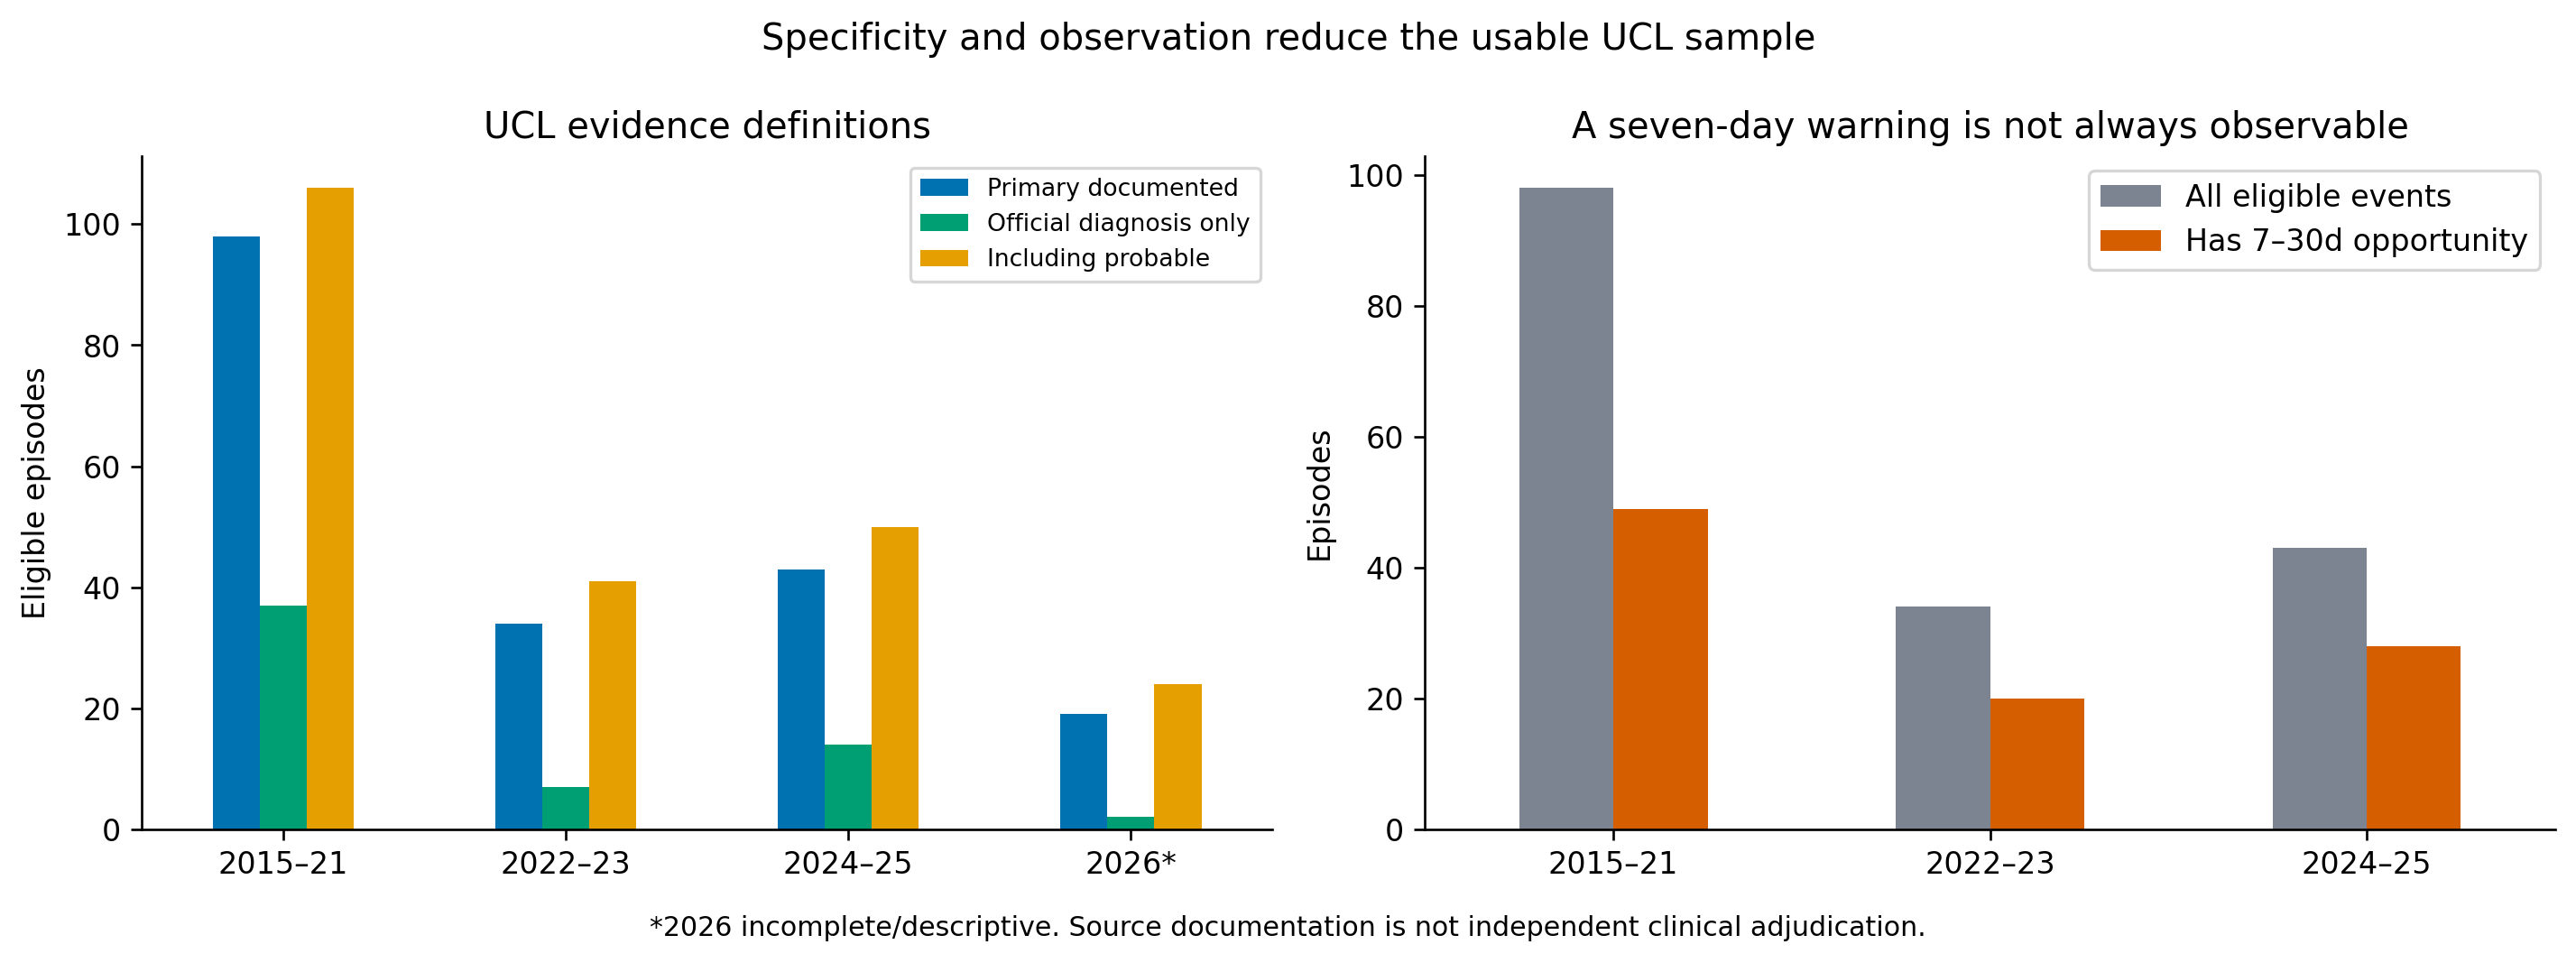

In [6]:
plot('01_endpoint_and_opportunity')

**Interpretation:** 194 eligible primary events remain, but only 20/34 validation and 28/43 exploratory-transfer events have a 7–30-day prediction opportunity. All eligible events stay in the principal recall denominator. Surgery-linked ascertainment and unknown contemporaneous publication history remain limitations. The official-only subset is too small for confident independent modeling.

In [7]:
show('feature_representations', rows=16)
show('trajectory_feature_support', rows=15)

,representation,feature,derivation,timing
0,Background,throws_left,unchanged frozen existing field,after completed outing; historical terms stric...
1,Background,age_at_appearance,unchanged frozen existing field,after completed outing; historical terms stric...
2,Background,days_since_mlb_debut,unchanged frozen existing field,after completed outing; historical terms stric...
3,Background,observed_prior_mlb_appearances,unchanged frozen existing field,after completed outing; historical terms stric...
4,Background,observed_prior_mlb_starts,unchanged frozen existing field,after completed outing; historical terms stric...
5,Background,prior_reported_il_count,unchanged frozen existing field,after completed outing; historical terms stric...
6,Background,calendar_month,unchanged frozen existing field,after completed outing; historical terms stric...
7,Profile,avg_fb_velo_baseline_mean,unchanged frozen existing field,after completed outing; historical terms stric...
8,Profile,release_x_avg_baseline_mean,unchanged frozen existing field,after completed outing; historical terms stric...
9,Profile,release_z_avg_baseline_mean,unchanged frozen existing field,after completed outing; historical terms stric...


,partition,season,dyn_velo_z_slope4,dyn_velo_z_absmean4,dyn_velo_z_persist4,dyn_release_z_sd_z_slope4,dyn_release_z_sd_z_absmean4,dyn_release_z_sd_z_persist4,dyn_extension_z_slope4,dyn_extension_z_absmean4,dyn_extension_z_persist4,dyn_spin_z_slope4,dyn_spin_z_absmean4,dyn_spin_z_persist4
0,descriptive_2026,2026,0.802084,0.802084,0.802084,0.812341,0.812341,0.812341,0.820481,0.820481,0.820481,0.817930,0.817930,0.817930
1,test,2024,0.805960,0.805960,0.805960,0.816929,0.816929,0.816929,0.821345,0.821345,0.821345,0.812900,0.812900,0.812900
2,test,2025,0.799103,0.799103,0.799103,0.814052,0.814052,0.814052,0.825143,0.825143,0.825143,0.817524,0.817524,0.817524
3,train,2015,0.691899,0.691899,0.691899,0.697166,0.697166,0.697166,0.702784,0.702784,0.702784,0.699824,0.699824,0.699824
4,train,2016,0.799871,0.799871,0.799871,0.805931,0.805931,0.805931,0.808216,0.808216,0.808216,0.805434,0.805434,0.805434
5,train,2017,0.806201,0.806201,0.806201,0.814258,0.814258,0.814258,0.830225,0.830225,0.830225,0.829785,0.829785,0.829785
6,train,2018,0.803284,0.803284,0.803284,0.805177,0.805177,0.805177,0.825289,0.825289,0.825289,0.824011,0.824011,0.824011
7,train,2019,0.793149,0.793149,0.793149,0.802615,0.802615,0.802615,0.820423,0.820423,0.820423,0.819673,0.819673,0.819673
8,train,2020,0.668853,0.668853,0.668853,0.670998,0.670998,0.670998,0.679828,0.679828,0.679828,0.679828,0.679828,0.679828
9,train,2021,0.795395,0.795395,0.795395,0.806394,0.806394,0.806394,0.815157,0.815157,0.815157,0.813991,0.813991,0.813991
